<a href="https://colab.research.google.com/github/AYA-747/Dijkstra-Step-by-Step-Comprendre-le-plus-court-chemin-en-console-et-en-graphique/blob/main/Classification_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import json
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
!pip install kaggle

In [ ]:
kaggle_data = {
    "username": "bechaya",
    "key": "KGAT_78c8eb94ee96621e0fcd954ef71a42cf"
}

# créer le dossier kaggle
os.makedirs("/root/.kaggle", exist_ok=True)

# créer kaggle.json
with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump(kaggle_data, f)

# donner les permissions
os.chmod("/root/.kaggle/kaggle.json", 600)

print("kaggle.json créé avec succès !")


kaggle.json créé avec succès !


In [ ]:
!kaggle datasets list -s vehicule

ref                                                    title                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
-----------------------------------------------------  ----------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
hamandekoursangama/vehicule-detection                  Vehicule detection                   276484960  2025-06-15 13:14:54.257000              3          0  0.375            
massinissatinouche/vahicule-fuel-type-california-2022  Vahicule Fuel Type California 2022     3415250  2023-06-02 05:49:58.067000             30          1  0.7647059        
haitamelaframe/vehicules-fusion-dataset                vehicules_fusion_dataset             374411998  2024-12-01 12:35:16.217000              3          0  0.1875           
alexcolmenero/vehicules-dataset                        Vehicules_dataset                    166402246  2024-05-26 21:39:26.43

In [ ]:
!kaggle datasets download -d bechaya/vehicles-type

Dataset URL: https://www.kaggle.com/datasets/bechaya/vehicles-type
License(s): CC0-1.0
 98% 710M/726M [00:07<00:00, 211MB/s]
100% 726M/726M [00:07<00:00, 105MB/s]


In [ ]:
!unzip vehicles-type.zip -d vehicles-type

Archive:  vehicles-type.zip
  inflating: vehicles-type/Vehicles-types/Bikes/Bike (1).jpg  
  inflating: vehicles-type/Vehicles-types/Bikes/Bike (10).jpg  
  inflating: vehicles-type/Vehicles-types/Bikes/Bike (100).jpg  
  inflating: vehicles-type/Vehicles-types/Bikes/Bike (101).jpg  
  inflating: vehicles-type/Vehicles-types/Bikes/Bike (102).jpg  
  inflating: vehicles-type/Vehicles-types/Bikes/Bike (103).jpg  
  inflating: vehicles-type/Vehicles-types/Bikes/Bike (104).jpg  
  inflating: vehicles-type/Vehicles-types/Bikes/Bike (105).jpg  
  inflating: vehicles-type/Vehicles-types/Bikes/Bike (106).jpg  
  inflating: vehicles-type/Vehicles-types/Bikes/Bike (107).jpg  
  inflating: vehicles-type/Vehicles-types/Bikes/Bike (108).jpg  
  inflating: vehicles-type/Vehicles-types/Bikes/Bike (109).jpg  
  inflating: vehicles-type/Vehicles-types/Bikes/Bike (11).jpg  
  inflating: vehicles-type/Vehicles-types/Bikes/Bike (110).jpg  
  inflating: vehicles-type/Vehicles-types/Bikes/Bike (111).jpg  
 

In [ ]:
os.listdir("/content/vehicles-type/Vehicles-types")

['Planes', 'Ships', 'Trains', 'Motorcycles', 'Cars', 'Bikes']

In [ ]:
train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "/content/vehicles-type/Vehicles-types",
    image_size=(48, 48),
    batch_size=32,
    validation_split=0.2,   # 20% pour test
    subset="training",
    seed=123
)

test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "/content/vehicles-type/Vehicles-types",
    image_size=(48, 48),
    batch_size=32,
    validation_split=0.2,
    subset="validation",
    seed=123
)

Found 4788 files belonging to 6 classes.
Using 3831 files for training.
Found 4788 files belonging to 6 classes.
Using 957 files for validation.


In [ ]:
train_images, train_labels = zip(*[(x, y) for x, y in train_dataset])
test_images, test_labels = zip(*[(x, y) for x, y in test_dataset])

train_images = np.concatenate([x.numpy() for x in train_images])
train_labels = np.concatenate([y.numpy() for y in train_labels])

test_images = np.concatenate([x.numpy() for x in test_images])
test_labels = np.concatenate([y.numpy() for y in test_labels])

In [ ]:
train_images = train_images / 255.0
test_images = test_images / 255.0

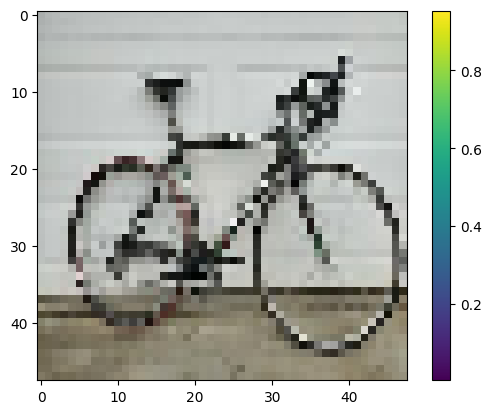

In [ ]:
# Afficher une image du dataset de train
plt.figure()
plt.imshow(train_images[0])
plt.colorbar()
plt.grid(False)
plt.show()

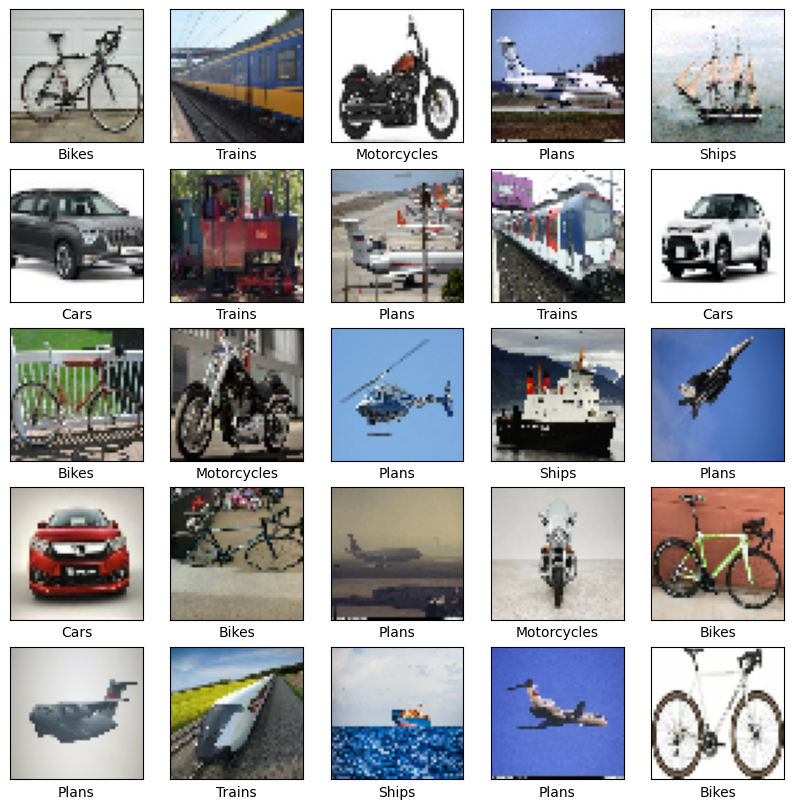

In [ ]:
# Liste des noms des classes
class_names = ["Bikes", "Cars", "Motorcycles", "Plans", "Ships", "Trains"]

plt.figure(figsize=(10,10))  # Définir la taille de la figure
for i in range(25):  # Afficher 25 images
    plt.subplot(5, 5, i+1)  # Créer une grille 5x5
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

    # Affichage de l'image en niveaux de gris
    plt.imshow(train_images[i], cmap="gray")

    # Ajouter un label correspondant à la classe
    plt.xlabel(class_names[train_labels[i]])

plt.show()

In [ ]:
model = tf.keras.Sequential([
    # Première couche de convolution
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(48, 48, 3)),  # 3 canaux pour les images RGB
    tf.keras.layers.MaxPooling2D(2,2),

    # Deuxième couche de convolution
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    # Troisième couche de convolution
    tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    # Aplatir et ajouter des couches entièrement connectées
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(6, activation='softmax')
    ])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [ ]:
history = model.fit(
    train_images ,
    train_labels ,
    epochs=10,
    validation_data=(test_images, test_labels)
)

Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/backend/tensorflow/nn.py:717: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


120/120 ━━━━━━━━━━━━━━━━━━━━ 16s 121ms/step - accuracy: 0.3277 - loss: 1.6064 - val_accuracy: 0.6708 - val_loss: 0.9844
Epoch 2/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 13s 112ms/step - accuracy: 0.6766 - loss: 0.8983 - val_accuracy: 0.7482 - val_loss: 0.7651
Epoch 3/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 21s 113ms/step - accuracy: 0.7161 - loss: 0.7708 - val_accuracy: 0.7179 - val_loss: 0.8027
Epoch 4/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 20s 112ms/step - accuracy: 0.7756 - loss: 0.6328 - val_accuracy: 0.7712 - val_loss: 0.6516
Epoch 5/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 14s 116ms/step - accuracy: 0.8098 - loss: 0.5394 - val_accuracy: 0.7931 - val_loss: 0.5952
Epoch 6/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 20s 112ms/step - accuracy: 0.8364 - loss: 0.4889 - val_accuracy: 0.7952 - val_loss: 0.5750
Epoch 7/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 22s 127ms/step - accuracy: 0.8654 - loss: 0.3903 - val_accuracy: 0.8474 - val_loss: 0.4600
Epoch 8/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 19s 116ms/step - accuracy: 0.8963 - loss: 0.3203 - val

In [ ]:
# Évaluation du modèle sur les données de test
test_loss, test_accuracy = model.evaluate(test_images, test_labels)

# Affichage de l'exactitude et de la perte
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.8506 - loss: 0.4857
Test Loss: 0.5480
Test Accuracy: 82.65%


In [ ]:
probability_model = tf.keras.Sequential([
    model,
    tf.keras.layers.Softmax()  # Transformation des logits en probabilités
])
predictions = probability_model.predict(test_images)

30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step


In [ ]:
# Affichage du vecteur de prédictions
predictions[0]

array([0.15490076, 0.13848926, 0.2229778 , 0.138875  , 0.14182569,
       0.2029316 ], dtype=float32)

In [ ]:
# Identification de la classe prédite
np.argmax(predictions[0])

np.int64(2)

In [ ]:
# Comparaison avec l'étiquette réelle
test_labels[0]

np.int32(0)

In [ ]:
class_names = ["Bikes", "Cars", "Motorcycles", "Plans", "Ships", "Trains"]

# Function to plot an image
def plot_image(i, predictions_array, true_label, img):
    true_label, img = true_label[i], img[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])

    plt.imshow(img, cmap=plt.cm.binary)

    predicted_label = np.argmax(predictions_array)
    if predicted_label == true_label:
        color = 'blue'
    else:
        color = 'red'

    plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label],
                                         100 * np.max(predictions_array),
                                         class_names[true_label]),
                 color=color)

# Function to plot the bar chart for the predicted class probabilities
def plot_value_array(i, predictions_array, true_label):
    true_label = true_label[i]
    plt.grid(False)
    plt.xticks(range(6))
    plt.yticks([])
    thisplot = plt.bar(range(6), predictions_array, color="#777777")
    plt.ylim([0, 1])
    predicted_label = np.argmax(predictions_array)

    thisplot[predicted_label].set_color('red')
    thisplot[true_label].set_color('blue')


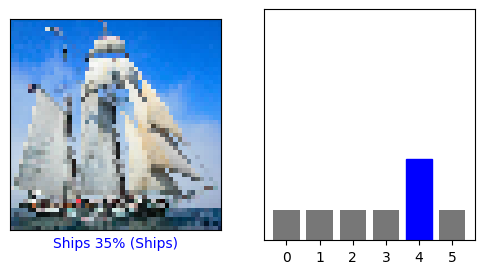

In [ ]:
i = 1
# Plot the image and value array for a given index
plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plot_image(i, predictions[i], test_labels, test_images)
plt.subplot(1, 2, 2)
plot_value_array(i, predictions[i], test_labels)
plt.show()

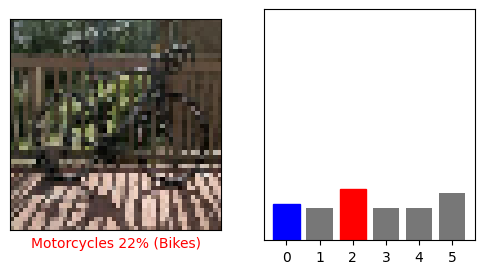

In [ ]:
i = 0
# Plot the image and value array for a given index
plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plot_image(i, predictions[i], test_labels, test_images)
plt.subplot(1, 2, 2)
plot_value_array(i, predictions[i], test_labels)
plt.show()

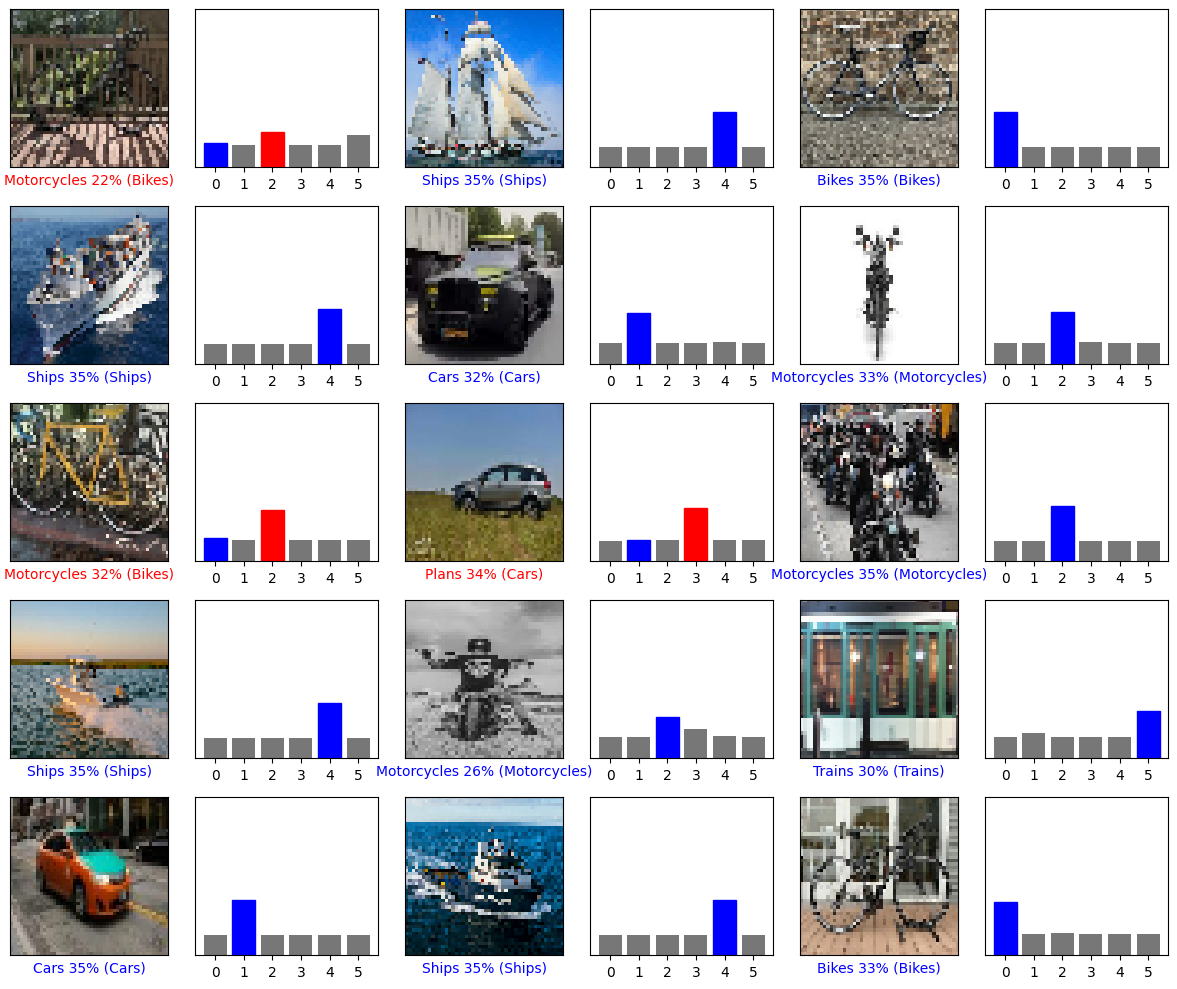

In [ ]:
num_rows = 5
num_cols = 3
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_image(i, predictions[i], test_labels, test_images)
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_value_array(i, predictions[i], test_labels)
plt.tight_layout()
plt.show()

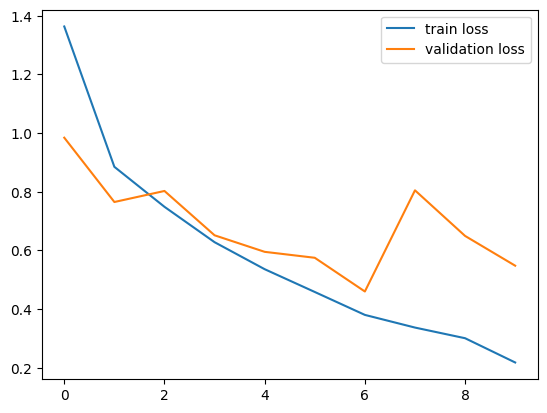

In [ ]:
plt.plot(history.history['loss'],label='train loss')
plt.plot(history.history['val_loss'],label='validation loss')
plt.legend()
plt.show()

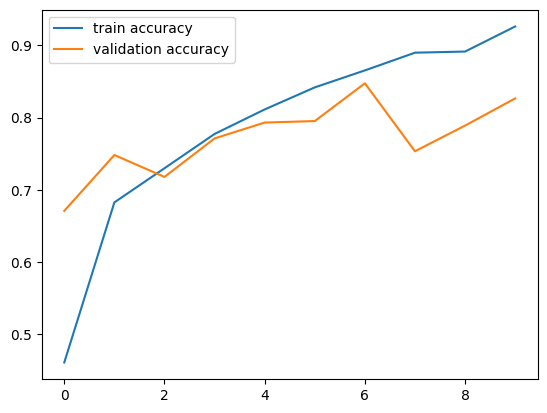

In [ ]:
plt.plot(history.history['accuracy'],label='train accuracy')
plt.plot(history.history['val_accuracy'], label='validation accuracy')
plt.legend()
plt.show()